<a href="https://colab.research.google.com/github/rodriguesa2009/Miniprojeto/blob/main/M%C3%B3dulo_1_Projeto_Avaliativo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# fase 1

In [1]:
!apt-get -y update
!apt-get -y install postgresql postgresql-contrib
!service postgresql start

!sudo -u postgres psql -c "ALTER USER postgres WITH PASSWORD 'teste123';"
!sudo -u postgres psql -c "CREATE DATABASE portal_transparencia;"

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:3 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:6 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:11 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Get:12 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,111 kB]
Get:13 http://security.ubuntu.com/ubuntu noble-security/restricted amd64 Packages [2,132 kB]
Get:14 ht

In [2]:
import psycopg2
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
DIRETORIO_ARQUIVOS = "/content/drive/MyDrive/viajem_2025_6meses"

In [5]:
def conectar_banco():
    return psycopg2.connect(**DB_CONFIG)

In [6]:
import pandas as pd
import os

arquivos = [
    "2025_Viagem.csv",
    "2025_Pagamento.csv",
    "2025_Passagem.csv",
    "2025_Trecho.csv"
]

for arquivo in arquivos:
    caminho = os.path.join(DIRETORIO_ARQUIVOS, arquivo)
    df = pd.read_csv(
        caminho,
        sep=";",
        encoding="ISO-8859-1",
        nrows=0
    )
    print(f"\n{arquivo}:")
    print(df.columns.tolist())


2025_Viagem.csv:
['Identificador do processo de viagem', 'Número da Proposta (PCDP)', 'Situação', 'Viagem Urgente', 'Justificativa Urgência Viagem', 'Código do órgão superior', 'Nome do órgão superior', 'Código órgão solicitante', 'Nome órgão solicitante', 'CPF viajante', 'Nome', 'Cargo', 'Função', 'Descrição Função', 'Período - Data de início', 'Período - Data de fim', 'Destinos', 'Motivo', 'Valor diárias', 'Valor passagens', 'Valor devolução', 'Valor outros gastos']

2025_Pagamento.csv:
['Identificador do processo de viagem', 'Número da Proposta (PCDP)', 'Código do órgão superior', 'Nome do órgão superior', 'Codigo do órgão pagador', 'Nome do órgao pagador', 'Código da unidade gestora pagadora', 'Nome da unidade gestora pagadora', 'Tipo de pagamento', 'Valor']

2025_Passagem.csv:
['Identificador do processo de viagem', 'Número da Proposta (PCDP)', 'Meio de transporte', 'País - Origem ida', 'UF - Origem ida', 'Cidade - Origem ida', 'País - Destino ida', 'UF - Destino ida', 'Cidade - 

# fase 2

In [7]:
DB_CONFIG = {
    "dbname": "portal_transparencia",
    "user": "postgres",
    "password": "teste123",
    "host": "localhost",
    "port": "5432" }

In [8]:
RAW_ARQUIVOS_E_TABELAS = {
    "2025_Pagamento.csv": "raw_pagamento",
    "2025_Passagem.csv": "raw_passagem",
    "2025_Trecho.csv": "raw_trecho",
    "2025_Viagem.csv": "raw_viagem"
}

In [9]:
df_raw_separado = pd.DataFrame({
    'Arquivo_CSV': list(RAW_ARQUIVOS_E_TABELAS.keys())
}).join(pd.DataFrame({
    'Tabela_Raw': list(RAW_ARQUIVOS_E_TABELAS.values())
}))

In [10]:
SILVER_ARQUIVOS_E_TABELAS = {
    "2025_Pagamento.csv": "silver_pagamento",
    "2025_Passagem.csv": "silver_passagem",
    "2025_Trecho.csv": "silver_trecho",
    "2025_Viagem.csv": "silver_viagem"
}

In [11]:
df_silver_separado = pd.DataFrame({
    'Arquivo_CSV': list(SILVER_ARQUIVOS_E_TABELAS.keys())
}).join(pd.DataFrame({
    'Tabela_Silver': list(SILVER_ARQUIVOS_E_TABELAS.values())
}))

In [12]:
def importar_dados_raw():
    conn = None
    cursor = None

    try:
        conn = psycopg2.connect(**DB_CONFIG)
        cursor = conn.cursor()
        for nome_arquivo, nome_tabela in RAW_ARQUIVOS_E_TABELAS.items():
            caminho_completo = os.path.join(
                DIRETORIO_ARQUIVOS,
                nome_arquivo
            )
            if not os.path.exists(caminho_completo):
                raise FileNotFoundError(
                    f"Arquivo não encontrado: {caminho_completo}"
                )
            try:
                cursor.execute(
                    f"TRUNCATE TABLE {nome_tabela} RESTART IDENTITY CASCADE;"
                )
                with open(
                    caminho_completo,
                    "r",
                    encoding="ISO-8859-1"
                ) as arquivo_aberto:
                    cursor.copy_expert(
                        f"COPY {nome_tabela} "
                        "FROM STDIN WITH "
                        "(FORMAT CSV, HEADER TRUE, DELIMITER ';')",
                        arquivo_aberto
                    )

                conn.commit()

            except Exception:
                conn.rollback()
                raise
    finally:
        if cursor is not None:
            cursor.close()
        if conn is not None:
            conn.close()

In [13]:
import os
import pandas as pd
import psycopg2

def criar_tabelas_e_processar_pipeline():
    global DIRETORIO_ARQUIVOS
    DIRETORIO_ARQUIVOS = "/content/drive/MyDrive/viajem_2025_6meses"
    conn = None
    cursor = None
    try:
        conn = psycopg2.connect(**DB_CONFIG)
        cursor = conn.cursor()
        for nome_arquivo, nome_tabela in RAW_ARQUIVOS_E_TABELAS.items():
            caminho_completo = os.path.join(DIRETORIO_ARQUIVOS, nome_arquivo)
            if not os.path.exists(caminho_completo):
                raise FileNotFoundError(f"Arquivo não encontrado: {caminho_completo}")
            colunas = pd.read_csv(caminho_completo, sep=";", encoding="ISO-8859-1", nrows=0).columns.tolist()
            definicoes_colunas = ", ".join('"' + coluna.replace('"', '""') + '" VARCHAR' for coluna in colunas)
            cursor.execute(f"CREATE TABLE IF NOT EXISTS {nome_tabela} ({definicoes_colunas});")
        conn.commit()
        cursor.execute("""
            CREATE TABLE IF NOT EXISTS silver_viagem (
                id_viagem VARCHAR(100) PRIMARY KEY NOT NULL,
                num_proposta VARCHAR(50),
                situacao VARCHAR(50),
                viagem_urgente VARCHAR(10),
                codigo_orgao_superior VARCHAR(50),
                nome_orgao_superior VARCHAR(255) NOT NULL,
                nome_viajante VARCHAR(255),
                cargo VARCHAR(255),
                data_inicio DATE,
                data_fim DATE,
                destinos VARCHAR(4000),
                motivo VARCHAR(4000),
                valor_diarias DECIMAL(12,2) CHECK (valor_diarias >= 0),
                valor_passagens DECIMAL(12,2) CHECK (valor_passagens >= 0),
                valor_devolucao DECIMAL(12,2) CHECK (valor_devolucao >= 0),
                valor_outros_gastos DECIMAL(12,2) CHECK (valor_outros_gastos >= 0),
                valor_total DECIMAL(14,2),
                duracao_dias INT CHECK (duracao_dias >= 0)
            );
            CREATE TABLE IF NOT EXISTS silver_pagamento (
                id_pagamento SERIAL PRIMARY KEY,
                id_viagem VARCHAR(100) NOT NULL REFERENCES silver_viagem(id_viagem),
                num_proposta VARCHAR(50),
                nome_orgao_pagador VARCHAR(255),
                nome_ug_pagadora VARCHAR(255),
                tipo_pagamento VARCHAR(100) NOT NULL,
                valor DECIMAL(12,2) CHECK (valor >= 0)
            );
            CREATE TABLE IF NOT EXISTS silver_passagem (
                id_passagem SERIAL PRIMARY KEY,
                id_viagem VARCHAR(100) NOT NULL REFERENCES silver_viagem(id_viagem),
                meio_transporte VARCHAR(100),
                pais_origem_ida VARCHAR(100),
                uf_origem_ida VARCHAR(100),
                cidade_origem_ida VARCHAR(150),
                pais_destino_ida VARCHAR(100),
                uf_destino_ida VARCHAR(100),
                cidade_destino_ida VARCHAR(150),
                valor_passagem DECIMAL(12,2) CHECK (valor_passagem >= 0),
                taxa_servico DECIMAL(12,2) CHECK (taxa_servico >= 0),
                data_emissao DATE
            );
            CREATE TABLE IF NOT EXISTS silver_trecho (
                id_trecho SERIAL PRIMARY KEY,
                id_viagem VARCHAR(100) NOT NULL REFERENCES silver_viagem(id_viagem),
                sequencia_trecho INT,
                origem_data DATE,
                origem_uf VARCHAR(100),
                origem_cidade VARCHAR(150),
                destino_data DATE,
                destino_uf VARCHAR(100),
                destino_cidade VARCHAR(150),
                meio_transporte VARCHAR(100),
                numero_diarias DECIMAL(12,2) CHECK (numero_diarias >= 0),
                UNIQUE (id_viagem, sequencia_trecho)
            );
        """)
        conn.commit()
        cursor.close()
        conn.close()
        cursor = None
        conn = None

        importar_dados_raw()

        conn = psycopg2.connect(**DB_CONFIG)
        cursor = conn.cursor()
        cursor.execute("""
            TRUNCATE TABLE silver_pagamento, silver_passagem, silver_trecho, silver_viagem RESTART IDENTITY CASCADE;
        """)
        conn.commit()
        cursor.execute("""
            INSERT INTO silver_viagem (
                id_viagem, num_proposta, situacao, viagem_urgente, codigo_orgao_superior, nome_orgao_superior,
                nome_viajante, cargo, data_inicio, data_fim, destinos, motivo, valor_diarias, valor_passagens,
                valor_devolucao, valor_outros_gastos, valor_total, duracao_dias
            )
            SELECT
                TRIM(rv."Identificador do processo de viagem"), TRIM(rv."Número da Proposta (PCDP)"), TRIM(rv."Situação"),
                TRIM(rv."Viagem Urgente"), TRIM(rv."Código do órgão superior"), TRIM(rv."Nome do órgão superior"),
                TRIM(rv."Nome"), TRIM(rv."Cargo"),
                TO_DATE(NULLIF(TRIM(rv."Período - Data de início"), ''), 'DD/MM/YYYY'),
                TO_DATE(NULLIF(TRIM(rv."Período - Data de fim"), ''), 'DD/MM/YYYY'),
                TRIM(rv."Destinos"), TRIM(rv."Motivo"),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor diárias"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor passagens"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor devolução"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor outros gastos"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                COALESCE(CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor diárias"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)), 0)
                + COALESCE(CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor passagens"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)), 0)
                + COALESCE(CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor outros gastos"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)), 0)
                - COALESCE(CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rv."Valor devolução"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)), 0),
                TO_DATE(NULLIF(TRIM(rv."Período - Data de fim"), ''), 'DD/MM/YYYY') - TO_DATE(NULLIF(TRIM(rv."Período - Data de início"), ''), 'DD/MM/YYYY')
            FROM raw_viagem rv
            WHERE NULLIF(TRIM(rv."Identificador do processo de viagem"), '') IS NOT NULL
              AND NULLIF(TRIM(rv."Nome do órgão superior"), '') IS NOT NULL
            ON CONFLICT (id_viagem) DO NOTHING;
        """)
        conn.commit()
        cursor.execute("""
            INSERT INTO silver_trecho (
                id_viagem, sequencia_trecho, origem_data, origem_uf, origem_cidade, destino_data, destino_uf, destino_cidade, meio_transporte, numero_diarias
            )
            SELECT
                TRIM(rt."Identificador do processo de viagem "), CAST(NULLIF(TRIM(rt."Sequência Trecho"), '') AS INT),
                TO_DATE(NULLIF(TRIM(rt."Origem - Data"), ''), 'DD/MM/YYYY'), TRIM(rt."Origem - UF"), TRIM(rt."Origem - Cidade"),
                TO_DATE(NULLIF(TRIM(rt."Destino - Data"), ''), 'DD/MM/YYYY'), TRIM(rt."Destino - UF"), TRIM(rt."Destino - Cidade"),
                TRIM(rt."Meio de transporte"),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rt."Número Diárias"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2))
            FROM raw_trecho rt
            INNER JOIN silver_viagem sv ON TRIM(rt."Identificador do processo de viagem ") = sv.id_viagem
            WHERE NULLIF(TRIM(rt."Sequência Trecho"), '') IS NOT NULL
            ON CONFLICT (id_viagem, sequencia_trecho) DO NOTHING;
        """)
        conn.commit()
        cursor.execute("""
            INSERT INTO silver_pagamento (id_viagem, num_proposta, nome_orgao_pagador, nome_ug_pagadora, tipo_pagamento, valor)
            SELECT
                TRIM(rp."Identificador do processo de viagem"), TRIM(rp."Número da Proposta (PCDP)"), TRIM(rp."Nome do órgao pagador"),
                TRIM(rp."Nome da unidade gestora pagadora"), TRIM(rp."Tipo de pagamento"),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rp."Valor"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2))
            FROM raw_pagamento rp
            INNER JOIN silver_viagem sv ON TRIM(rp."Identificador do processo de viagem") = sv.id_viagem
            WHERE NULLIF(TRIM(rp."Tipo de pagamento"), '') IS NOT NULL;
        """)
        conn.commit()
        cursor.execute("""
            INSERT INTO silver_passagem (
                id_viagem, meio_transporte, pais_origem_ida, uf_origem_ida, cidade_origem_ida, pais_destino_ida, uf_destino_ida, cidade_destino_ida, valor_passagem, taxa_servico, data_emissao
            )
            SELECT
                TRIM(rpa."Identificador do processo de viagem"), TRIM(rpa."Meio de transporte"), TRIM(rpa."País - Origem ida"),
                TRIM(rpa."UF - Origem ida"), TRIM(rpa."Cidade - Origem ida"), TRIM(rpa."País - Destino ida"),
                TRIM(rpa."UF - Destino ida"), TRIM(rpa."Cidade - Destino ida"),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rpa."Valor da passagem"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                CAST(NULLIF(REPLACE(REPLACE(NULLIF(TRIM(rpa."Taxa de serviço"), ''), '.', ''), ',', '.'), '') AS DECIMAL(12,2)),
                TO_DATE(NULLIF(TRIM(rpa."Data da emissão/compra"), ''), 'DD/MM/YYYY')
            FROM raw_passagem rpa
            INNER JOIN silver_viagem sv ON TRIM(rpa."Identificador do processo de viagem") = sv.id_viagem;
        """)
        conn.commit()
    except Exception:
        if conn is not None and not conn.closed:
            conn.rollback()
        raise
    finally:
        if cursor is not None and not cursor.closed:
            cursor.close()
        if conn is not None and not conn.closed:
            conn.close()

In [14]:
criar_tabelas_e_processar_pipeline()

In [15]:
conn = psycopg2.connect(**DB_CONFIG)
cursor = conn.cursor()

for tabela in [
    "raw_viagem",
    "raw_pagamento",
    "raw_passagem",
    "raw_trecho",
    "silver_viagem",
    "silver_pagamento",
    "silver_passagem",
    "silver_trecho"
]:
    cursor.execute(f"SELECT COUNT(*) FROM {tabela}")
    print(f"{tabela}: {cursor.fetchone()[0]} registros")

cursor.close()
conn.close()

raw_viagem: 341860 registros
raw_pagamento: 606916 registros
raw_passagem: 167260 registros
raw_trecho: 763349 registros
silver_viagem: 341860 registros
silver_pagamento: 606916 registros
silver_passagem: 167260 registros
silver_trecho: 763349 registros


# fase 3

In [16]:
import psycopg2
import pandas as pd

def criar_camada_gold():
    conn = psycopg2.connect(**DB_CONFIG)
    cursor = conn.cursor()

    try:
        cursor.execute("""
            CREATE TABLE IF NOT EXISTS gold_resumo_viagens (
                id_resumo SERIAL PRIMARY KEY,
                nome_orgao_superior VARCHAR(255),
                nome_viajante VARCHAR(255),
                cargo VARCHAR(255),
                total_viagens INT,
                gasto_diarias DECIMAL(14,2),
                gasto_passagens DECIMAL(14,2),
                gasto_total_geral DECIMAL(14,2)
            );
        """)
        conn.commit()

        cursor.execute("TRUNCATE TABLE gold_resumo_viagens RESTART IDENTITY;")
        conn.commit()

        cursor.execute("""
            INSERT INTO gold_resumo_viagens (
                nome_orgao_superior, nome_viajante, cargo,
                total_viagens, gasto_diarias, gasto_passagens, gasto_total_geral
            )
            SELECT
                nome_orgao_superior,
                nome_viajante,
                cargo,
                COUNT(id_viagem) as total_viagens,
                SUM(valor_diarias) as gasto_diarias,
                SUM(valor_passagens) as gasto_passagens,
                SUM(valor_total) as gasto_total_geral
            FROM silver_viagem
            WHERE situacao = 'Realizada'
            GROUP BY nome_orgao_superior, nome_viajante, cargo;
        """)
        conn.commit()

    except Exception as e:
        conn.rollback()
        raise
    finally:
        cursor.close()
        conn.close()

criar_camada_gold()


In [17]:
conn = psycopg2.connect(**DB_CONFIG)

query_ouro = """
    SELECT nome_orgao_superior, SUM(gasto_total_geral) as investimento_total
    FROM gold_resumo_viagens
    GROUP BY nome_orgao_superior
    ORDER BY investimento_total DESC
    LIMIT 5;
"""

df_ouro = pd.read_sql_query(query_ouro, conn)
conn.close()

df_ouro

/tmp/ipykernel_1110/2255390572.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_ouro = pd.read_sql_query(query_ouro, conn)


,nome_orgao_superior,investimento_total
0,Ministério da Justiça e Segurança Pública,4.857482e+08
1,Ministério da Defesa,1.545959e+08
2,Ministério da Educação,1.097598e+08
3,Ministério do Meio Ambiente e Mudança do Clima,4.930060e+07
4,Ministério da Previdência Social,4.023618e+07


/tmp/ipykernel_1110/3714345902.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_orgaos = pd.read_sql_query(query_orgaos, conn)
/tmp/ipykernel_1110/3714345902.py:25: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_viajantes = pd.read_sql_query(query_viajantes, conn)
/tmp/ipykernel_1110/3714345902.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


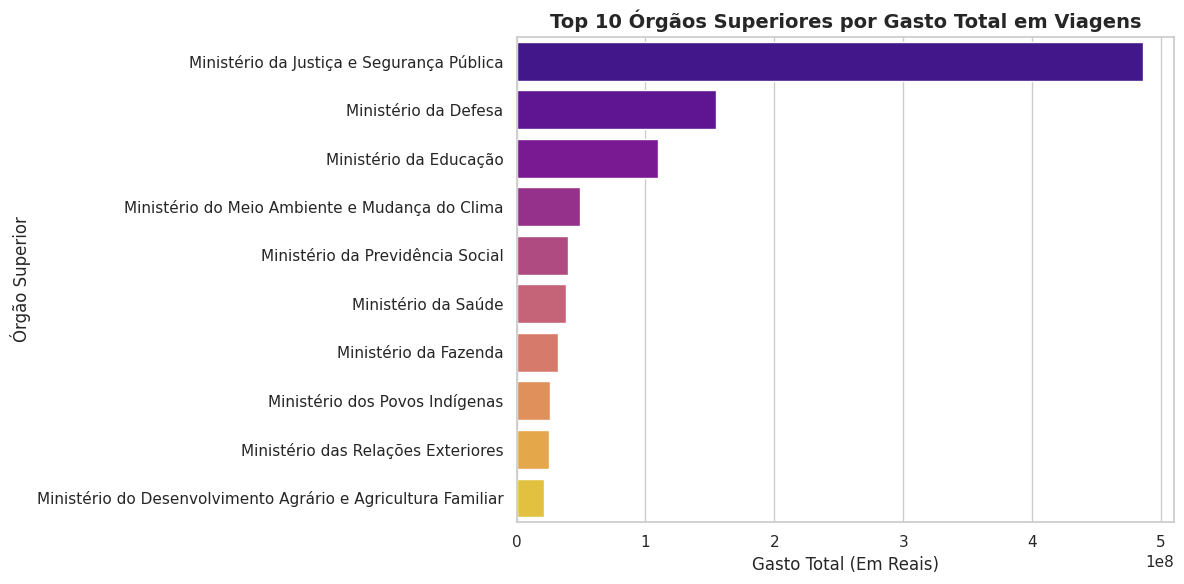

/tmp/ipykernel_1110/3714345902.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


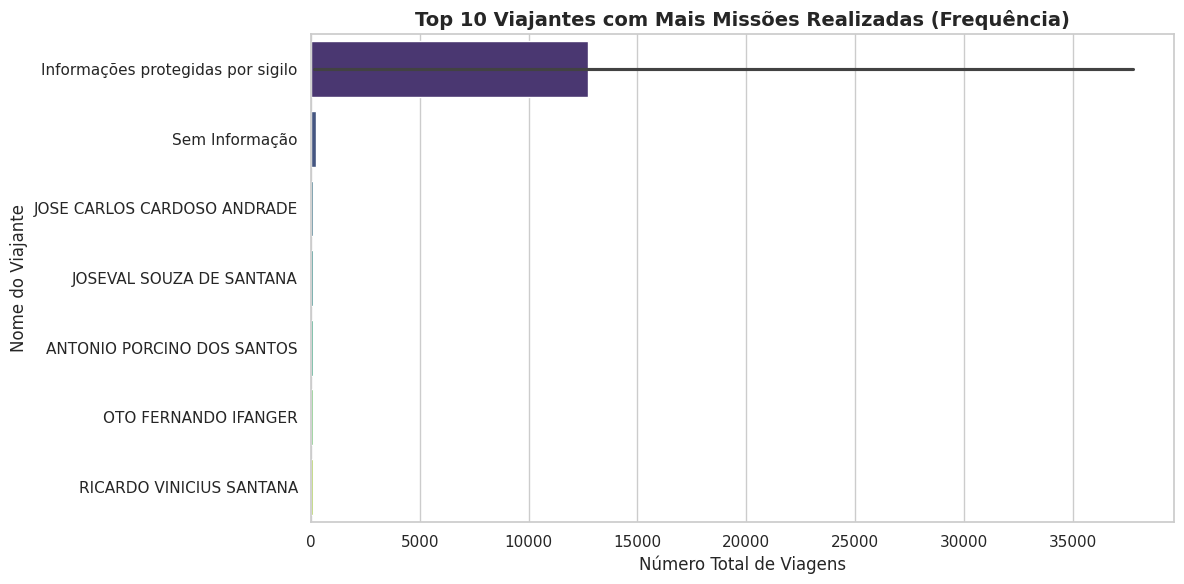

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import psycopg2

def gerar_graficos_analytics():
    conn = psycopg2.connect(**DB_CONFIG)

    query_orgaos = """
        SELECT nome_orgao_superior, SUM(gasto_total_geral) as gasto_total
        FROM gold_resumo_viagens
        GROUP BY nome_orgao_superior
        ORDER BY gasto_total DESC
        LIMIT 10;
    """
    df_orgaos = pd.read_sql_query(query_orgaos, conn)

    query_viajantes = """
        SELECT nome_viajante, total_viagens, cargo
        FROM gold_resumo_viagens
        WHERE nome_viajante IS NOT NULL AND nome_viajante != ''
        ORDER BY total_viagens DESC
        LIMIT 10;
    """
    df_viajantes = pd.read_sql_query(query_viajantes, conn)

    conn.close()

    sns.set_theme(style="whitegrid")

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=df_orgaos,
        x='gasto_total',
        y='nome_orgao_superior',
        palette='plasma'
    )
    plt.title('Top 10 Órgãos Superiores por Gasto Total em Viagens', fontsize=14, fontweight='bold')
    plt.xlabel('Gasto Total (Em Reais)', fontsize=12)
    plt.ylabel('Órgão Superior', fontsize=12)
    plt.tight_layout()
    plt.show()

    print("\n" + "="*80 + "\n")

    plt.figure(figsize=(12, 6))
    sns.barplot(
        data=df_viajantes,
        x='total_viagens',
        y='nome_viajante',
        palette='viridis'
    )
    plt.title('Top 10 Viajantes com Mais Missões Realizadas (Frequência)', fontsize=14, fontweight='bold')
    plt.xlabel('Número Total de Viagens', fontsize=12)
    plt.ylabel('Nome do Viajante', fontsize=12)
    plt.tight_layout()
    plt.show()

gerar_graficos_analytics()